# Algorithm implementation with AI · Kruskal’s minimum spanning tree

**Guiding question.** How can we prompt AI to implement a graph algorithm and then verify its result by hand and with a visual?

We will connect five sites with the smallest possible total link cost. The links are **undirected**, so a link between A and B connects both ways. Run the cells in order. The algorithm uses standard Python. The separate plotting section uses NetworkX and Matplotlib. If needed, run **%pip install networkx matplotlib** in a new cell.

## 1. The mathematical idea

A **spanning tree** connects every vertex and contains no cycle. 
- With $V$ vertices it has $V-1$ edges.
- A **minimum spanning tree (MST)** minimizes the sum of its edge weights.

Kruskal visits edges from smallest to largest weight. It **accepts** an edge when its endpoints are in different connected components and **rejects** it when they are already connected. Joining two components cannot create a cycle. Joining vertices in the same component would close a cycle.

**Why the greedy choice works.** Imagine a cut separating one current component from the rest of the graph. When Kruskal accepts the next edge, it is a lightest edge crossing such a cut. If a minimum tree that contains the earlier choices lacks this edge, add it to that tree. The resulting cycle contains another edge across the cut. You can remove that other edge without increasing the total cost, so some minimum tree contains the new choice.

## 2. Trace the example by hand

Start with five separate components, $\{A\},\{B\},\{C\},\{D\},\{E\}$. Cover the decision column and predict each step. The rows follow increasing weight.

| Edge | Weight | Decision | Reason |
| --- | ---: | --- | --- |
| A–B | 1 | Accept | Joins A and B. |
| B–C | 2 | Accept | Adds C to the component containing A and B. |
| A–C | 3 | Reject | A and C are already connected through B. |
| C–D | 4 | Accept | Adds D to the growing component. |
| B–D | 5 | Reject | B and D are already connected through C. |
| D–E | 6 | Accept | Adds E, completing the spanning tree. |
| C–E | 7 | Reject | C and E are already connected through D. |

The accepted edges have total weight $1+2+4+6=\mathbf{13}$. A solver can stop after the fourth acceptance. The classroom implementation continues through the edge list to record every decision.

## 3. Prompt AI to implement it

Paste this structured prompt into an AI assistant. Ask students to identify which phrase specifies the algorithm, which specifies the output, and which gives an independent way to check it.

> **Role.** Act as a Python tutor for graph theory students.  
> **Task.** Implement Kruskal’s algorithm in Python 3 for a weighted, undirected graph using only the standard library.  
> **Inputs.** Take a list of vertices and a list of (source, destination, weight) tuples. Assume each edge has valid endpoints and the vertex labels in this exercise are strings.  
> **Rules.** Sort by weight, preserving input order on ties. Use a disjoint-set structure with find and union. Accept an edge only when it joins different components. Inspect every edge so the trace includes all cycle rejections.  
> **Outputs.** Return the accepted edges, total weight, and a trace recording each edge and whether it was accepted or rejected. For disconnected graphs, return a minimum spanning forest. Keep plotting out of the function.  
> **Check.** For A–B=1, B–C=2, A–C=3, C–D=4, B–D=5, D–E=6, C–E=7, compare your trace with the hand solution. The expected accepted weights are 1, 2, 4, and 6. Explain each rejection.

The reference implementation below lets the class run the lesson without calling an AI service. Compare an AI implementation against the same hand trace and checks.

In [1]:
vertices = ["A", "B", "C", "D", "E"]
edges = [
    ("B", "D", 5), ("A", "B", 1), ("D", "E", 6),
    ("A", "C", 3), ("C", "E", 7), ("B", "C", 2), ("C", "D", 4),
]

## 4. Implement and check the result

The disjoint-set structure stores one parent per vertex. **find** follows parents to a component representative and shortens the path for later lookups. **union** joins two different components. Two vertices with the same representative are already connected.

In [2]:
def kruskal(vertices, edges):
    parent = {vertex: vertex for vertex in vertices}

    def find(vertex):
        while parent[vertex] != vertex:
            parent[vertex] = parent[parent[vertex]]
            vertex = parent[vertex]
        return vertex

    def union(a, b):
        root_a, root_b = find(a), find(b)
        if root_a == root_b:
            return False
        parent[root_b] = root_a
        return True

    selected, trace = [], []
    for u, v, weight in sorted(edges, key=lambda edge: edge[2]):
        edge = (u, v, weight)
        if union(u, v):
            selected.append(edge)
            trace.append((edge, "accept"))
        else:
            trace.append((edge, "reject"))

    total = sum(weight for _, _, weight in selected)
    return selected, total, trace

In [3]:
selected, total, trace = kruskal(vertices, edges)

for (u, v, weight), decision in trace:
    print(f"{u} – {v}   weight {weight}   {decision}")
print(f"Total weight: {total}")

expected = [("A", "B", 1), ("B", "C", 2), ("C", "D", 4), ("D", "E", 6)]
assert selected == expected
assert total == 13
assert len(selected) == len(vertices) - 1
assert [weight for (_, _, weight), decision in trace if decision == "reject"] == [3, 5, 7]
print("Matches the hand-worked trace.")

A – B   weight 1   accept
B – C   weight 2   accept
A – C   weight 3   reject
C – D   weight 4   accept
B – D   weight 5   reject
D – E   weight 6   accept
C – E   weight 7   reject
Total weight: 13
Matches the hand-worked trace.


## 5. Visual verification

Both panels use the same automatically computed layout. The left panel shows every candidate edge. The right panel shows the selected tree in teal and the rejected edges in pale dashed lines for reference.

Follow the teal lines from A to E, check that they contain no cycle, and add the four selected weights. The plot helps check connectivity and the sum. The cut argument explains why no lighter spanning tree exists.

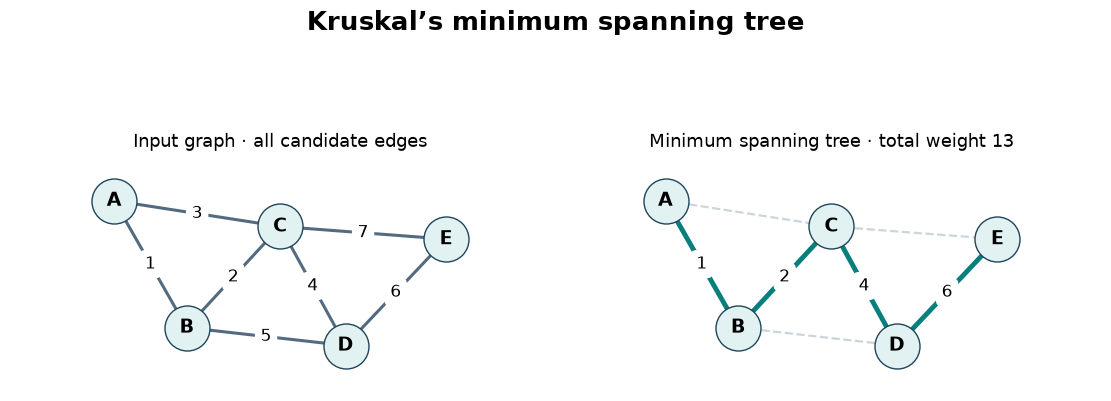

In [4]:
import matplotlib.pyplot as plt
import networkx as nx


def plot_kruskal(vertices, edges, selected):
    graph = nx.Graph()
    graph.add_nodes_from(vertices)
    graph.add_weighted_edges_from(edges)

    tree = nx.Graph()
    tree.add_nodes_from(vertices)
    tree.add_weighted_edges_from(selected)
    rejected = [(u, v) for u, v in graph.edges if not tree.has_edge(u, v)]
    positions = nx.spring_layout(graph, seed=12, weight=None)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
    left, right = axes
    nx.draw_networkx_edges(graph, positions, ax=left, edge_color="#526B80", width=2.2)
    nx.draw_networkx_edges(graph, positions, ax=right, edgelist=rejected,
                           edge_color="#CAD6DC", style="dashed", width=1.6)
    nx.draw_networkx_edges(tree, positions, ax=right, edge_color="#087F7D", width=3.5)

    for ax, labeled_graph in [(left, graph), (right, tree)]:
        nx.draw_networkx_nodes(graph, positions, ax=ax, node_color="#E2F1F2",
                               edgecolors="#20465A", node_size=1050)
        nx.draw_networkx_labels(graph, positions, ax=ax, font_size=14, font_weight="bold")
        nx.draw_networkx_edge_labels(
            labeled_graph, positions, ax=ax, rotate=False, font_size=12,
            edge_labels=nx.get_edge_attributes(labeled_graph, "weight"),
        )
        ax.margins(0.24)
        ax.set_aspect("equal")
        ax.axis("off")

    weight = sum(weight for _, _, weight in selected)
    label = "Minimum spanning tree" if nx.is_connected(tree) else "Minimum spanning forest"
    fig.suptitle("Kruskal’s minimum spanning tree", fontsize=19, fontweight="bold")
    left.set_title("Input graph · all candidate edges", fontsize=13)
    right.set_title(f"{label} · total weight {weight}", fontsize=13)
    return fig


figure = plot_kruskal(vertices, edges, selected)
plt.show()

## 6. Try it yourself

1. Change A–C from weight 3 to weight 0. Predict the accepted edges and new total by hand. Then run Kruskal and call the plotting function with the new result. The assertions in the worked example check the original data.
2. Add a separate vertex F with no edges. Explain why the result is a **minimum spanning forest**, even if the total weight stays the same.
3. Ask AI to implement early stopping for a connected graph. Compare the selected tree, total weight, and trace with the original version. Which edge decision will disappear from this example?